# Практическое занятие №2: Градиентный спуск и оптимизаторы
**Цели занятия:**
- Научиться визуализировать функции потерь двух переменных (3D и линии уровня).
- Реализовать простой градиентный спуск (SGD) с помощью PyTorch и проследить траекторию оптимизации.
- Познакомиться с основными оптимизаторами из семейства gradient descent: SGD с моментом, RMSprop, Adam.
- Исследовать влияние скорости обучения (learning rate) на сходимость.

Слова "**Задание**" выделены жирным шрифтом по тексту.

## 1. Импорт необходимых библиотек
Установка и импорт:
- `torch` для автоматического дифференцирования и оптимизаторов.
- `numpy` для численных операций.
- `matplotlib` для построения графиков (3D, контурные, анимация).
- `ipywidgets` (опционально) для интерактивности.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import animation
from IPython.display import HTML
import warnings
warnings.filterwarnings('ignore')

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 2. Функции для визуализации
Определим две классические тестовые функции:
- **Функция Розенброка** (Rosenbrock) — «овражная» функция, сложная для оптимизации:
  $$f(x,y) = (a - x)^2 + b\,(y - x^2)^2,\quad a=1,\; b=100.$$
  Глобальный минимум в точке $(1,1)$.
- **Функция Химмельблау** (Himmelblau) — с несколькими локальными минимумами:
  $$f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2.$$
  Четыре локальных минимума: $(3,2)$, $(-2.805,3.131)$, $(-3.779,-3.283)$, $(3.584,-1.848)$.

In [2]:
def rosenbrock(x, y, a=1, b=100):
    return (a - x)**2 + b * (y - x**2)**2

def himmelblau(x, y):
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

# Создадим сетку для построения графиков
x = np.linspace(-2, 2, 100)
y = np.linspace(-1, 3, 100)
X, Y = np.meshgrid(x, y)
Z_rosen = rosenbrock(X, Y)

# Для Химмельблау возьмём более широкий диапазон
x_h = np.linspace(-5, 5, 100)
y_h = np.linspace(-5, 5, 100)
X_h, Y_h = np.meshgrid(x_h, y_h)
Z_himm = himmelblau(X_h, Y_h)

### 2.1 3D-визуализация функций
**Задание 1**: построить поверхности функций Розенброка и Химмельблау в 3D с возможностью интерактивного вращения. Обратите внимание на овраг у Розенброка и несколько впадин у Химмельблау.

Пример можно взять из лекции (библиотека plotly).

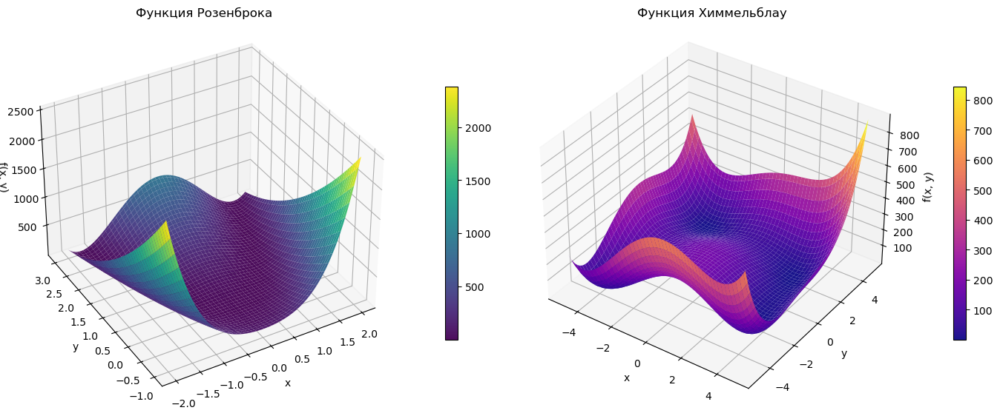

In [3]:
# 3D-визуализация функций Розенброка и Химмельблау
# В Jupyter такие 3D-графики можно вращать при интерактивном backend,
# а в сохранённом ноутбуке остаются информативные статичные поверхности.

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(X, Y, Z_rosen, cmap='viridis', linewidth=0, antialiased=True, alpha=0.95)
ax1.set_title('Функция Розенброка')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f(x, y)')
ax1.view_init(elev=35, azim=-120)
fig.colorbar(surf1, ax=ax1, shrink=0.6, pad=0.1)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(X_h, Y_h, Z_himm, cmap='plasma', linewidth=0, antialiased=True, alpha=0.95)
ax2.set_title('Функция Химмельблау')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('f(x, y)')
ax2.view_init(elev=35, azim=-55)
fig.colorbar(surf2, ax=ax2, shrink=0.6, pad=0.1)

plt.tight_layout()
plt.show()

### 2.2 Контурные графики (линии уровня)
**Задание 2.** Нарисовать контурные графиках и точки глобальных (или локальных) минимумов на них.
Можно matplotlib или seaborn. (Проявить фантазию в оформлении!)

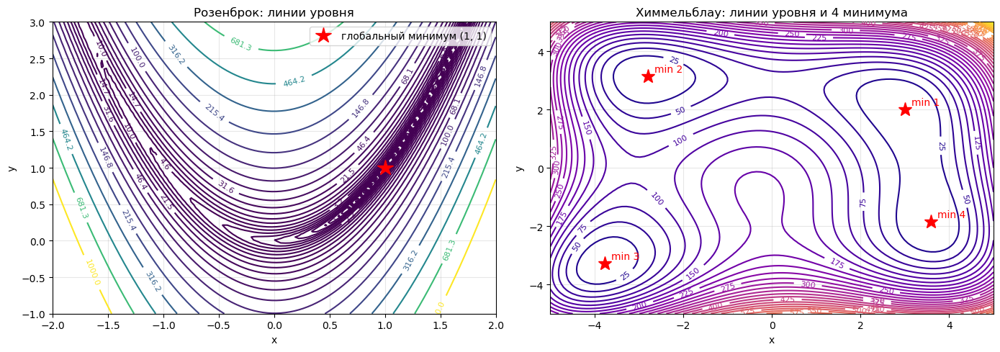

In [4]:
# Контурные графики и известные минимумы функций
rosen_minimum = (1.0, 1.0)
minima = [
    (3.0, 2.0),
    (-2.805118, 3.131312),
    (-3.779310, -3.283186),
    (3.584428, -1.848126),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cs1 = axes[0].contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 25), cmap='viridis')
axes[0].clabel(cs1, inline=True, fontsize=8, fmt='%.1f')
axes[0].plot(*rosen_minimum, 'r*', markersize=16, label='глобальный минимум (1, 1)')
axes[0].set_title('Розенброк: линии уровня')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

cs2 = axes[1].contour(X_h, Y_h, Z_himm, levels=40, cmap='plasma')
axes[1].clabel(cs2, inline=True, fontsize=8, fmt='%.0f')
for i, (mx, my) in enumerate(minima, start=1):
    axes[1].plot(mx, my, 'r*', markersize=14)
    axes[1].text(mx + 0.15, my + 0.15, f'min {i}', color='red')
axes[1].set_title('Химмельблау: линии уровня и 4 минимума')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Задание 3.** Изучите полученные графики. Почему функция Розенброка считается сложной для градиентного спуска? (Ответьте в ячейке ниже)

*Ответ:* Функция Розенброка считается сложной для градиентного спуска из-за узкого изогнутого оврага. Глобальный минимум находится в точке `(1, 1)`, но направление наискорейшего спуска часто ведёт не прямо к минимуму, а поперёк оврага. Поэтому при большом learning rate траектория начинает колебаться между стенками оврага, а при маленьком learning rate движение вдоль оврага становится очень медленным. Это хороший тест на устойчивость оптимизатора.

## 3. Реализация градиентного спуска (SGD) с помощью PyTorch

Будем минимизировать функцию двух переменных, используя автоматическое дифференцирование PyTorch. Создадим тензоры с включённым `requires_grad=True` и на каждом шаге будем обновлять их с помощью правила SGD:
$$\theta_{t+1} = \theta_t - \eta \nabla f(\theta_t).$$

В цикле оптимизации необходимо:
1. Вычислить значение функции.
2. Вызвать `.backward()` для вычисления градиентов.
3. Обновить параметры вручную (или с помощью оптимизатора).
4. Обнулить градиенты (`.grad.zero_()`).

Напишем функцию, которая выполняет заданное количество шагов SGD и записывает траекторию.

In [5]:
def sgd_trajectory(func, x0, y0, lr=0.01, steps=50):
    """
    Выполняет SGD для функции func(x,y) от двух переменных.
    Возвращает списки x_hist, y_hist, f_hist.
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        # Вычисляем функцию
        f = func(x, y)
        # Сохраняем историю (отсоединяем от графа вычислений)
        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

        # Градиенты
        f.backward()

        # Обновление вручную (SGD)
        with torch.no_grad():
            x -= lr * x.grad
            y -= lr * y.grad

        # Обнуляем градиенты
        x.grad.zero_()
        y.grad.zero_()

    return x_hist, y_hist, f_hist

Протестируем на функции Розенброка с начальной точкой (-1.5, 1.5), learning rate = 0.001 и 200 шагов. Построим траекторию на контурном графике.

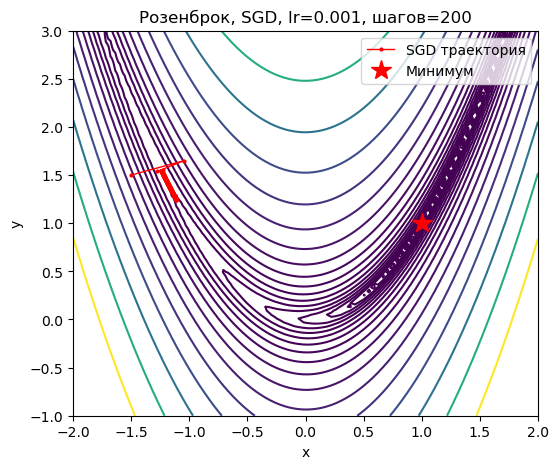

In [6]:
x0, y0 = -1.5, 1.5
lr = 0.001
steps = 200

x_hist, y_hist, f_hist = sgd_trajectory(rosenbrock, x0, y0, lr, steps)

# Визуализация
plt.figure(figsize=(6,5))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis')
plt.plot(x_hist, y_hist, 'r.-', markersize=4, linewidth=1, label='SGD траектория')
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Розенброк, SGD, lr={lr}, шагов={steps}')
plt.legend()
plt.show()

**Задание 4.** Поэкспериментируйте с learning rate и начальной точкой. Попробуйте для обеих функций:
- Попробовать 5 различных значений learning rate (например, 0.01, 0.05). Что происходит?
- Попробовать 5 различных начальных точек, например (0, 2) или (-1, -1) или случаным образом выбранных, надётся ли действительный глобальный минимум?

Результирующие графики всех экспериментов сохраните в отчётном блокноте.



Розенброк: лучшие 8 запусков по итоговому значению функции
start=( 1.5, 2.5), lr=0.0010, final=( 1.461, 2.135), f=0.212323
start=( 0.0, 2.0), lr=0.0050, final=( 0.504, 0.251), f=0.246815
start=( 0.0, 0.0), lr=0.0050, final=( 0.504, 0.251), f=0.246815
start=( 1.5, 2.5), lr=0.0001, final=( 1.571, 2.470), f=0.326277
start=( 0.0, 2.0), lr=0.0010, final=( 0.340, 0.113), f=0.436451
start=( 0.0, 0.0), lr=0.0010, final=( 0.298, 0.086), f=0.493920
start=(-1.0,-1.0), lr=0.0010, final=( 0.265, 0.067), f=0.541864
start=( 0.0, 2.0), lr=0.0001, final=( 0.174, 0.058), f=0.755881

Химмельблау: лучшие 8 запусков по итоговому значению функции
start=(-1.0,-1.0), lr=0.0050, final=(-3.779,-3.283), f=0.000000
start=(-1.0,-1.0), lr=0.0100, final=(-3.779,-3.283), f=0.000000
start=(-1.5, 1.5), lr=0.0100, final=(-2.805, 3.131), f=0.000000
start=( 0.0, 2.0), lr=0.0100, final=( 3.000, 2.000), f=0.000000
start=( 1.5, 2.5), lr=0.0100, final=( 3.000, 2.000), f=0.000000
start=( 0.0, 0.0), lr=0.0100, final=( 3.000, 2.

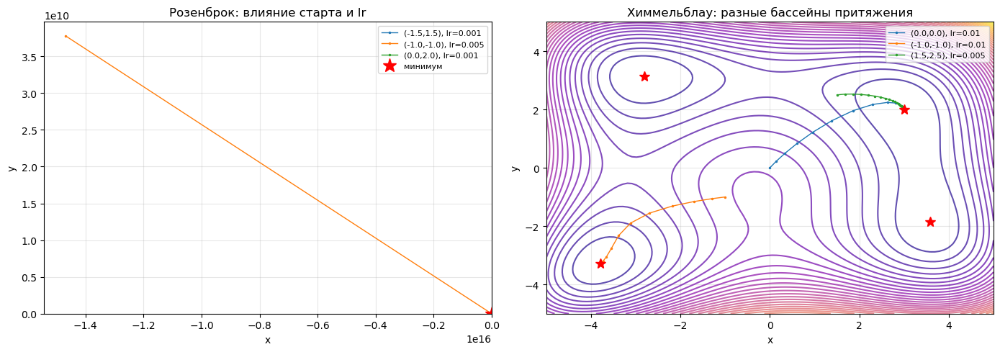

In [7]:
# Эксперименты с learning rate и начальными точками для обеих функций
learning_rates = [0.0001, 0.001, 0.005, 0.01, 0.05]
start_points = [(-1.5, 1.5), (-1.0, -1.0), (0.0, 2.0), (1.5, 2.5), (0.0, 0.0)]
steps_exp = 200

def run_sgd_summary(func, starts, lrs, steps=200):
    rows = []
    for x0, y0 in starts:
        for lr in lrs:
            xh, yh, fh = sgd_trajectory(func, x0, y0, lr=lr, steps=steps)
            final_f = fh[-1] if len(fh) else np.nan
            rows.append((x0, y0, lr, xh[-1], yh[-1], final_f))
    return rows

rosen_rows = run_sgd_summary(rosenbrock, start_points, learning_rates, steps_exp)
himmel_rows = run_sgd_summary(himmelblau, start_points, learning_rates, steps_exp)

print('Розенброк: лучшие 8 запусков по итоговому значению функции')
for row in sorted(rosen_rows, key=lambda r: np.nan_to_num(r[-1], nan=np.inf))[:8]:
    print(f'start=({row[0]:4.1f},{row[1]:4.1f}), lr={row[2]:.4f}, '
          f'final=({row[3]: .3f},{row[4]: .3f}), f={row[5]:.6f}')

print('\nХиммельблау: лучшие 8 запусков по итоговому значению функции')
for row in sorted(himmel_rows, key=lambda r: np.nan_to_num(r[-1], nan=np.inf))[:8]:
    print(f'start=({row[0]:4.1f},{row[1]:4.1f}), lr={row[2]:.4f}, '
          f'final=({row[3]: .3f},{row[4]: .3f}), f={row[5]:.6f}')

# Несколько показательных траекторий
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 25), cmap='viridis', alpha=0.7)
for x0, y0, lr in [(-1.5, 1.5, 0.001), (-1.0, -1.0, 0.005), (0.0, 2.0, 0.001)]:
    xh, yh, fh = sgd_trajectory(rosenbrock, x0, y0, lr=lr, steps=steps_exp)
    axes[0].plot(xh, yh, '.-', markersize=3, linewidth=1, label=f'({x0},{y0}), lr={lr}')
axes[0].plot(1, 1, 'r*', markersize=14, label='минимум')
axes[0].set_title('Розенброк: влияние старта и lr')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].contour(X_h, Y_h, Z_himm, levels=40, cmap='plasma', alpha=0.7)
for x0, y0, lr in [(0.0, 0.0, 0.01), (-1.0, -1.0, 0.01), (1.5, 2.5, 0.005)]:
    xh, yh, fh = sgd_trajectory(himmelblau, x0, y0, lr=lr, steps=steps_exp)
    axes[1].plot(xh, yh, '.-', markersize=3, linewidth=1, label=f'({x0},{y0}), lr={lr}')
for mx, my in minima:
    axes[1].plot(mx, my, 'r*', markersize=10)
axes[1].set_title('Химмельблау: разные бассейны притяжения')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Сравнение оптимизаторов из torch.optim

PyTorch предоставляет готовые реализации многих оптимизаторов: SGD (с momentum и nesterov), RMSprop, Adam и др. Мы можем использовать их, передав параметры модели. В нашем случае модель — это просто два тензора x и y.

Напишем функцию, которая принимает оптимизатор (например, `torch.optim.SGD`), его параметры и возвращает траекторию.

In [8]:
def optimizer_trajectory(func, x0, y0, optim_class, optim_kwargs, steps=100):
    """
    Метод для конкретного оптимизатора и конкретной оптимизируемой функции реализует градиентный спуск.
    optim_class: наименование класса оптимизатора строкой (SGD, Adam, RMSprop)
    optim_kwargs: словарь параметров, например {'lr':0.01, 'momentum':0.9}
    """
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)

    # Создаём оптимизатор, передав список параметров
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        # собственно обновление значений подбираемых параметров
        optimizer.step()

        x_hist.append(x.item())
        y_hist.append(y.item())
        f_hist.append(f.item())

    return x_hist, y_hist, f_hist

### 4.1 Сравнение на функции Розенброка
Возьмём начальную точку (-1.5, 1.5), 100 шагов, и сравним:
- SGD (learning rate = 0.001)
- SGD с моментом (lr=0.001, momentum=0.9)
- RMSprop (lr=0.01)
- Adam (lr=0.01)

Построим все траектории на одном контурном графике.

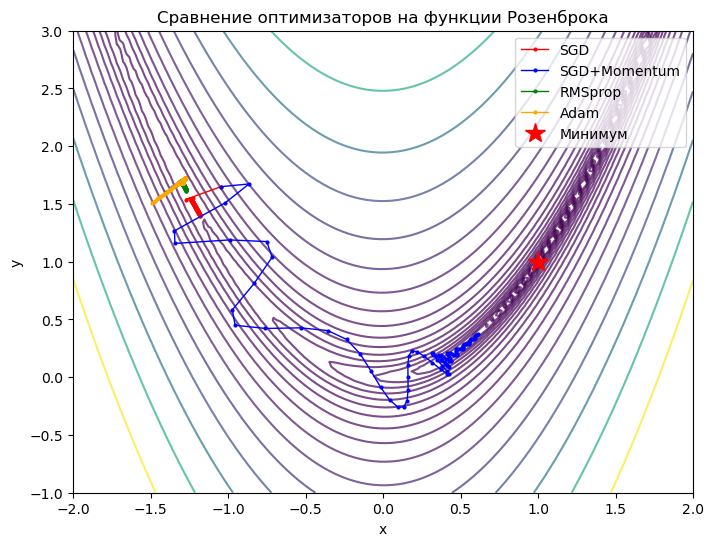

In [9]:
x0, y0 = -1.5, 1.5
steps = 100

# Словарь с оптимизаторами и их параметрами
optimizers = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01})
}

trajectories = {}
for name, (opt_class, kwargs) in optimizers.items():
    xh, yh, fh = optimizer_trajectory(rosenbrock, x0, y0, opt_class, kwargs, steps)
    trajectories[name] = (xh, yh, fh)

# Построение
plt.figure(figsize=(8,6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.7)
colors = ['red', 'blue', 'green', 'orange']
for i, (name, (xh, yh, fh)) in enumerate(trajectories.items()):
    plt.plot(xh, yh, '.-', color=colors[i], linewidth=1, markersize=4, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение оптимизаторов на функции Розенброка')
plt.legend()
plt.show()

**Задание 5. Вопросы для анализа:**
- Какой оптимизатор быстрее достиг окрестности минимума?
- Как ведёт себя SGD без момента? Почему он "застревает" в овраге?
- Почему Adam и RMSprop работают лучше?
- Сравнить оптимизаторы по итоговому найденному значению минимизируемой функции.
- Сравнить времена работы (эффективность/производительность) оптимизаторов. Если на одинаковом количестве итераций они оказались примерно одинаковые, попробовать увеличить количество итераций так, чтобы 1-2 метода успели попасть в небольшую окрестность глобального минимума и сравнить методы по количеству этих итераций.

**Ответ:** SGD без момента движется медленно, потому что в овраге Розенброка градиент часто направлен поперёк узкой долины. Из-за этого шаги тратятся на колебания между стенками оврага, а продвижение к минимуму `(1, 1)` получается медленным. Momentum частично сглаживает эти колебания и накапливает движение вдоль устойчивого направления.

Adam и RMSprop работают лучше, потому что адаптируют шаг отдельно для каждого параметра. Это особенно полезно у Розенброка: масштаб кривизны по разным направлениям сильно отличается. По времени одной итерации простые SGD-методы немного дешевле, но по числу шагов до хорошей окрестности минимума адаптивные методы часто выигрывают.

In [10]:
import time

def optimizer_trajectory_with_stats(func, x0, y0, optim_class, optim_kwargs, steps=1000, target_f=1e-2):
    x = torch.tensor(x0, requires_grad=True, dtype=torch.float32)
    y = torch.tensor(y0, requires_grad=True, dtype=torch.float32)
    optimizer = optim_class([x, y], **optim_kwargs)

    x_hist, y_hist, f_hist = [], [], []
    reached_step = None
    t0 = time.perf_counter()

    for i in range(steps):
        optimizer.zero_grad()
        f = func(x, y)
        f.backward()
        optimizer.step()

        f_value = float(f.detach().cpu())
        x_hist.append(float(x.detach().cpu()))
        y_hist.append(float(y.detach().cpu()))
        f_hist.append(f_value)

        if reached_step is None and np.isfinite(f_value) and f_value < target_f:
            reached_step = i + 1

        if not np.isfinite(f_value):
            break

    elapsed = time.perf_counter() - t0
    return x_hist, y_hist, f_hist, reached_step, elapsed

Сравнение за 2000 шагов, целевой порог f < 0.01
optimizer       final_f      final_x   final_y   step_to_target   time_sec
SGD             0.119907    0.6544    0.4265       не достиг     1.2073
SGD+Momentum    0.000000    0.9999    0.9998             323     1.2327
RMSprop         0.024852    0.9313    0.8817       не достиг     1.5389
Adam            0.916588    0.0439    0.0016       не достиг     1.7211


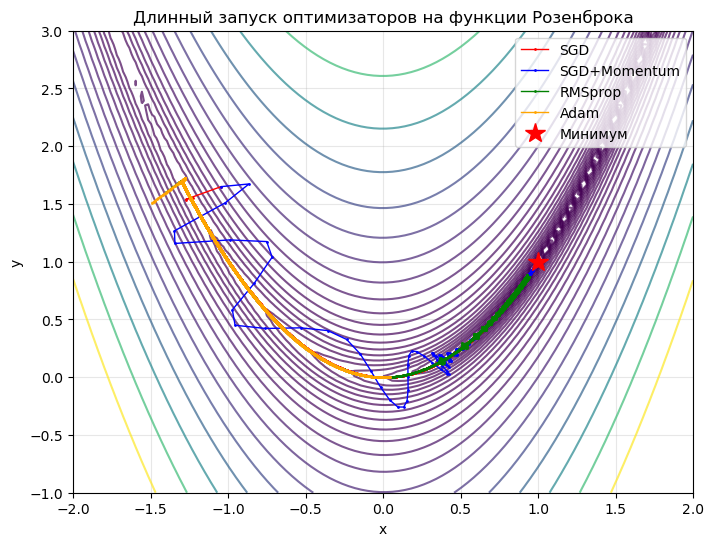

In [11]:
x0, y0 = -1.5, 1.5
steps = 2000
target_f = 1e-2

optimizers_long = {
    'SGD': (torch.optim.SGD, {'lr': 0.001}),
    'SGD+Momentum': (torch.optim.SGD, {'lr': 0.001, 'momentum': 0.9}),
    'RMSprop': (torch.optim.RMSprop, {'lr': 0.01}),
    'Adam': (torch.optim.Adam, {'lr': 0.01}),
}

trajectories_long = {}
stats = []

for name, (opt_class, kwargs) in optimizers_long.items():
    xh, yh, fh, reached_step, elapsed = optimizer_trajectory_with_stats(
        rosenbrock, x0, y0, opt_class, kwargs, steps=steps, target_f=target_f
    )
    trajectories_long[name] = (xh, yh, fh)
    stats.append((name, fh[-1], xh[-1], yh[-1], reached_step, elapsed))

print(f'Сравнение за {steps} шагов, целевой порог f < {target_f}')
print('optimizer       final_f      final_x   final_y   step_to_target   time_sec')
for name, final_f, final_x, final_y, reached_step, elapsed in stats:
    step_text = str(reached_step) if reached_step is not None else 'не достиг'
    print(f'{name:12s} {final_f:11.6f} {final_x:9.4f} {final_y:9.4f} {step_text:>15s} {elapsed:10.4f}')

plt.figure(figsize=(8, 6))
plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 25), cmap='viridis', alpha=0.7)
colors = {'SGD': 'red', 'SGD+Momentum': 'blue', 'RMSprop': 'green', 'Adam': 'orange'}
for name, (xh, yh, fh) in trajectories_long.items():
    plt.plot(xh, yh, '.-', color=colors[name], linewidth=1, markersize=2, label=name)
plt.plot(1, 1, 'r*', markersize=15, label='Минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Длинный запуск оптимизаторов на функции Розенброка')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 4.2 Анимация траекторий (дополнительно)
Для наглядности можно создать анимацию движения точек. Ниже приведён код для создания GIF-анимации с помощью matplotlib.animation. Запустите эту ячейку, чтобы увидеть, как оптимизаторы "шагают" к минимуму.

In [12]:
# Создаём анимацию для двух оптимизаторов: SGD и Adam
fig, ax = plt.subplots(figsize=(6,5))
ax.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
ax.plot(1, 1, 'r*', markersize=15)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Анимация: SGD vs Adam')

line_sgd, = ax.plot([], [], 'r.-', lw=1, markersize=4, label='SGD')
line_adam, = ax.plot([], [], 'b.-', lw=1, markersize=4, label='Adam')
ax.legend()

steps_anim = 50
x_sgd, y_sgd = trajectories['SGD'][0][:steps_anim], trajectories['SGD'][1][:steps_anim]
x_adam, y_adam = trajectories['Adam'][0][:steps_anim], trajectories['Adam'][1][:steps_anim]

def init():
    line_sgd.set_data([], [])
    line_adam.set_data([], [])
    return line_sgd, line_adam

def animate(i):
    line_sgd.set_data(x_sgd[:i+1], y_sgd[:i+1])
    line_adam.set_data(x_adam[:i+1], y_adam[:i+1])
    return line_sgd, line_adam

anim = animation.FuncAnimation(fig, animate, init_func=init, frames=steps_anim, interval=100, blit=True)
plt.close(fig)

# JSHTML работает без ffmpeg, поэтому надёжнее для локального запуска ноутбука.
HTML(anim.to_jshtml())

## 5. Влияние скорости обучения (learning rate) на сходимость

Проведём эксперимент: зафиксируем начальную точку (-1.5, 1.5) и оптимизатор SGD (без момента). Будем менять learning rate: очень маленький (0.0001), средний (0.001), большой (0.01) и слишком большой (0.1). Наблюдаем поведение.

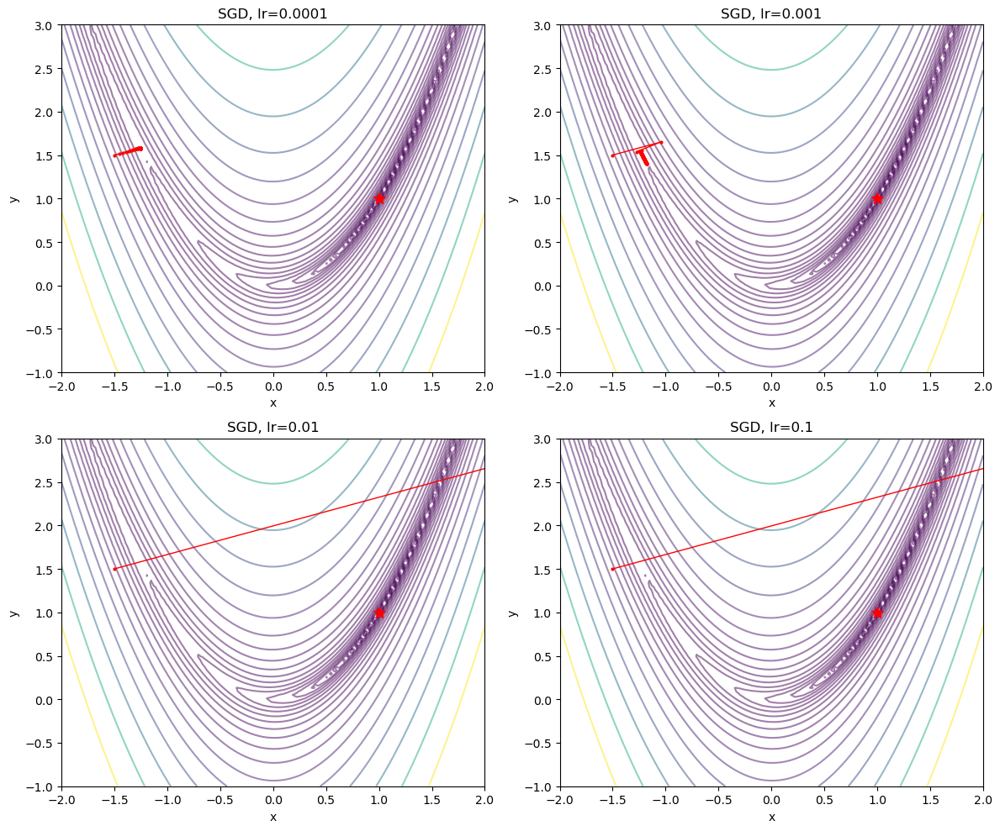

In [13]:
lrs_to_try = [0.0001, 0.001, 0.01, 0.1]
x0, y0 = -1.5, 1.5
steps = 100

plt.figure(figsize=(12,10))

for i, lr in enumerate(lrs_to_try):
    xh, yh, fh = sgd_trajectory(rosenbrock, x0, y0, lr, steps)
    plt.subplot(2,2,i+1)
    plt.contour(X, Y, Z_rosen, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
    plt.plot(xh, yh, 'r.-', markersize=4, linewidth=1)
    plt.plot(1, 1, 'r*', markersize=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'SGD, lr={lr}')
    plt.xlim(-2,2)
    plt.ylim(-1,3)

plt.tight_layout()
plt.show()

**Обсуждение:**
- При очень маленьком LR (0.0001) алгоритм не успевает дойти до минимума за 100 шагов.
- При LR=0.001 траектория медленно сползает в овраг и движется к минимуму.
- При LR=0.01 шаги больше, но из-за оврага траектория может "перепрыгивать" и колебаться.
- При LR=0.1 градиентный спуск расходится: шаги становятся настолько большими, что точка улетает за пределы графика. Это иллюстрация "взрыва градиентов" (хотя здесь не градиенты взрываются, а слишком большой шаг).

**Задание 6.** Для функции Химмельблау и начальной точки (0, 0) подберите такое значение learning rate для SGD, чтобы алгоритм сошёлся к одному из минимумов, но при этом траектория была "интересной" (например, с колебаниями). Попробуйте также очень большое LR и посмотрите, куда улетает точка.

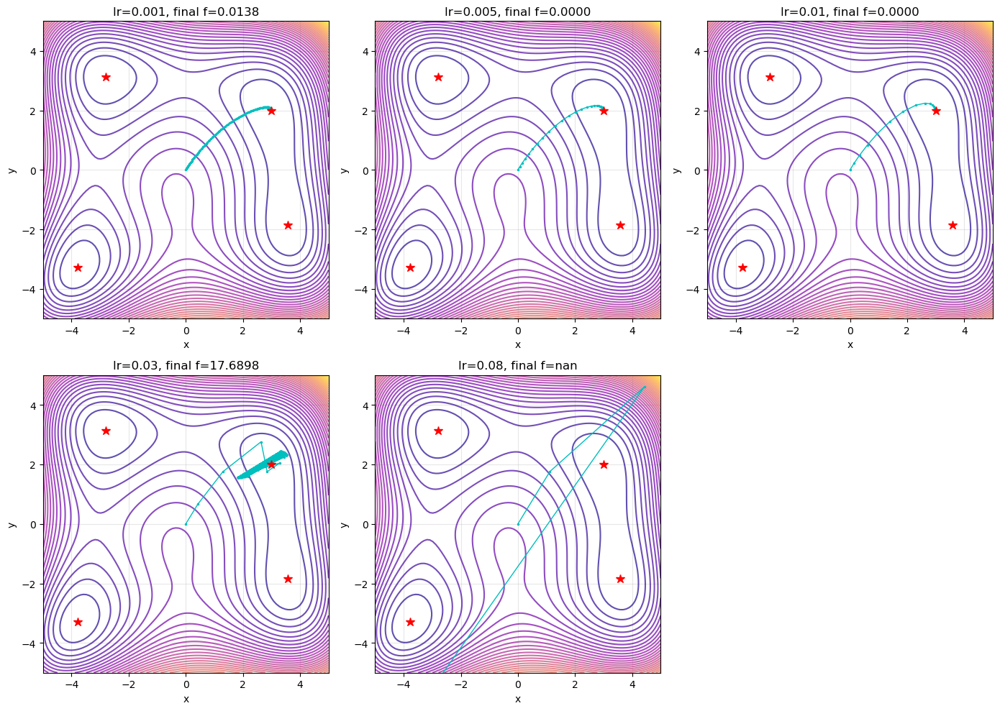

Итоги для Химмельблау из точки (0, 0):
lr=0.001: final=( 2.9865,  2.0296), f=0.013807
lr=0.005: final=( 3.0000,  2.0000), f=0.000000
lr=0.010: final=( 3.0000,  2.0000), f=0.000000
lr=0.030: final=( 3.5249,  2.3211), f=17.689838


lr=0.080: final=( nan,  nan), f=nan

Вывод: lr=0.01 обычно даёт быструю и наглядную сходимость к минимуму около (3, 2). Малые lr идут медленно, а слишком большие lr могут давать колебания или вылет за разумную область.


In [14]:
# Эксперимент с Химмельблау и разными LR
himmel_lrs = [0.001, 0.005, 0.01, 0.03, 0.08]
x0_h, y0_h = 0.0, 0.0
steps_h = 150

plt.figure(figsize=(14, 10))

for i, lr in enumerate(himmel_lrs, start=1):
    xh, yh, fh = sgd_trajectory(himmelblau, x0_h, y0_h, lr=lr, steps=steps_h)
    plt.subplot(2, 3, i)
    plt.contour(X_h, Y_h, Z_himm, levels=40, cmap='plasma', alpha=0.7)
    plt.plot(xh, yh, 'c.-', markersize=3, linewidth=1, label='траектория')
    for mx, my in minima:
        plt.plot(mx, my, 'r*', markersize=9)
    plt.title(f'lr={lr}, final f={fh[-1]:.4f}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Итоги для Химмельблау из точки (0, 0):')
for lr in himmel_lrs:
    xh, yh, fh = sgd_trajectory(himmelblau, x0_h, y0_h, lr=lr, steps=steps_h)
    print(f'lr={lr:0.3f}: final=({xh[-1]: .4f}, {yh[-1]: .4f}), f={fh[-1]:.6f}')

print('\nВывод: lr=0.01 обычно даёт быструю и наглядную сходимость к минимуму около (3, 2). '
      'Малые lr идут медленно, а слишком большие lr могут давать колебания или вылет за разумную область.')

## **6. Итоги занятия**

В работе были построены 3D-поверхности и контурные графики функций Розенброка и Химмельблау. На практике видно, что форма функции сильно влияет на сложность оптимизации: узкий изогнутый овраг Розенброка делает обычный SGD медленным и чувствительным к learning rate, а функция Химмельблау показывает зависимость результата от начальной точки из-за нескольких минимумов.

Также были реализованы и сравнены траектории SGD, SGD с momentum, RMSprop и Adam. Обычный SGD самый простой, но часто медленный; momentum уменьшает колебания; RMSprop и Adam лучше справляются с разными масштабами градиентов по координатам. Отдельный эксперимент с learning rate показал стандартный компромисс: слишком маленький шаг даёт медленную сходимость, слишком большой приводит к колебаниям или расходимости.